# Case Study 29 — Automating Food-Delivery Support with LLM Agents: Containment, Latency, CSAT and the Cost of Over-Containment

**Priority:** ★★ Good to have · **Reference:** Case Study 29 — *Zomato: Zia and Nugget support automation* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Customer Experience, Operations, Product (support), Finance, Trust and Safety
**Data:** ⚠️ **SYNTHETIC** (D-29-01). Support tickets, chat logs and CSAT scores are confidential; this is a simulation with hidden "needs a human", abuse and safety labels.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs29_support_automation_resolution.ipynb`

## 0. Executive Summary for Business

*(Synthetic support tickets with hidden truth, built on the documented structure of Zomato's LLM support bot as narrated by vendors: LLM-only escalation was unstable and a policy layer was added. The vendors' numbers (2x CSAT, 85% resolution, under 10 seconds) are unaudited and none is reproduced. Public method detail is thin, so this is an interview-standard solution on simulated data, not a reproduction of Zomato's system. Written after the analysis.)*

- **The question:** can LLM agents resolve most order-support tickets quickly and safely, and what do we lose when we chase containment?
- **Containment overstates resolution.** With the policy layer, naive containment is **69.0%** (CI 68.7% to 69.3%) but the share of tickets the bot truly resolved is **60.8%**, and the observable proxy (no abandonment, no re-contact in 72 hours) is 59.5%. Of the tickets the bot kept, **6.6% were abandoned and 11.4% came back within 72 hours**.
- **The policy layer stabilised the day-to-day swings.** Daily containment under LLM-only escalation had an SD of **12.6 points (range 51% to 89%)**; with the policy layer it was **2.2 points (64% to 72%)**. The SD ratio is 5.8 (bootstrap CI 3.9 to 7.7; Levene p < 1e-6). Intent mix and lateness explain only 10% of the LLM-only swings. The price: mean containment fell from 71.5% to 69.0%.
- **CSAT rose modestly, not 2x.** Top-2-box among survey responders: **53.2% (legacy), 58.9% (LLM-only), 59.4% (policy layer)**, a risk ratio of 1.12 (CI 1.08 to 1.15) for policy vs legacy. Only about 13% of customers answer the survey, so these are survey-conditional numbers.
- **The randomised holdout is more sobering.** Against human-first routing the bot pipeline has **lower true resolution (89.6% vs 92.6%, difference -3.0 pp, CI -3.8 to -2.2)**, worst for payment issues (-9.0 pp, Holm p = 0.0003), account issues, food quality and missing items. It wins on speed (median **7.8 s vs 328 s**) and on survey top-2-box (59.6% vs 48.2% after non-response weighting), and speed explains it: each extra minute of waiting lowers the odds of a 4 or 5 by 4%.
- **Over-containment and safety:** the policy layer cut tickets wrongly kept by the bot from 8.8% to 6.5% and the share of safety tickets kept by the bot from **37.6% to 4.5%**. A wrongly kept ticket is **10.9 times** as likely to come back.
- **Refund abuse:** approval of abusive refund requests fell from **74.7% to 43.0%**; leakage per 1,000 refund tickets from ₹8,269 to ₹4,912, with friction on legitimate requests slightly lower (32% vs 35%).
- **ML:** a failure model for bot-kept tickets is weak (AUC **0.64**), but escalating its riskiest 5% beats random escalation: true resolution 91.0% vs 89.6% and a lower cost per ticket (₹39.3 vs ₹41.4). Beyond about 5% extra escalation the cost rises again.
- **Money (assumed unit costs):** the policy layer saves about **₹148 crore a year in the base case (range ₹93 to ₹231 crore)** against the legacy tree at 1 crore contacts a month; LLM-only saves ₹124 crore in the base case.
- **I recommend:** keep the policy layer, keep a 5% human-first holdout permanently, add the extra 5% model-based escalation in shadow mode first, treat safety and payment issues as human-first, and report true-resolution and holdout CSAT beside containment.

## 1. The Problem in Simple English

When a food order goes wrong, the customer opens the app and chats with support. Most of those chats are simple ("where is my order?") and a bot can answer them in seconds. Some are not: a safety complaint, a payment dispute, a rude rider, or a refund request from an account that abuses refunds. The company wants the bot to handle as many chats as possible (**containment**) because a human chat costs far more, but it also wants customers to leave **satisfied** (**CSAT**) and **not come back** with the same problem.

The trap is that containment is easy to raise and easy to misread. A bot can "contain" a chat by being the last thing the customer talks to, even if the customer gave up. Leaders and interviewers want to know:
1. What exactly counts as **resolved**, and how far is plain containment from it?
2. Why did containment **swing from day to day** when the LLM alone decided when to escalate, and did a policy layer fix it?
3. Did CSAT really improve, and how do we know without a **randomised holdout**?
4. How much faster is the bot, and does speed explain CSAT?
5. Where does the bot **over-contain** (keep tickets that needed a human), including safety issues and refund abuse?
6. What escalation threshold gives the best balance of cost and resolution?

## 2. Reference from the Case File

### (a) What Zomato reported — *documented, vendor-published, unaudited*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Support cost grew to about US$20M a year, spread over 10 platforms (MongoDB case study, vendor-authored). Zomato handles over a million orders a day with meal-time spikes of 10 to 50 times baseline traffic (Together AI story, adapted from a Fifth Elephant 2024 talk) |
| Approach | Function classification then function calling to fetch order data; the answer is composed from order data, chat history and policy text. Larger (70B) models detect intent, smaller (8B) models complete the chat. First version used GPT-4, then Llama 3 |
| Escalation | With LLM-only escalation decisions, containment is reported to have swung between 80% and 50% day to day (paraphrase by the fetch tool, not a verbatim quote); a policy layer was added to stabilise it |
| Evaluation | Human review of every change, human grading of a sample, LLM-as-judge on four metrics: factual consistency, relevance, guideline compliance, pain-point resolution |
| Reported impact | CSAT "roughly doubled", average response time down 75% to under 10 seconds (Together AI); "85%" average query resolution rate, support cost from US$20M to about US$9M (MongoDB). No audited numbers, no control group, no statistical tests documented |
| Conflict | A search result suggested a different CSAT figure (a 25% improvement) from another vendor page; it was not fetched, so the "2x" is treated as unreconciled |

**Sources:** Together AI customer story on Zomato (Zia); MongoDB blog, "Zomato Cuts $11M in Support Costs With MongoDB-Powered AI Platform" (24 March 2026).

**Evidence level: medium (vendor-narrated).** Public method detail is thin: no definitions of containment or CSAT, no experiment design, no model accuracy. This notebook is an **interview-standard solution on simulated data**, not a reproduction of Zomato's system. The documented numbers above are context only and none of them is used to calibrate results.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 56 days of order-support tickets (about 180,000), three regimes: **legacy decision-tree bot**, **LLM-only escalation**, **LLM plus policy layer** with a **5% randomised human-first holdout**. Nine intents, hidden "needs a human", abuse and safety flags, CSAT survey with non-response, 72-hour re-contact, refund amounts |
| Statistics added | Containment funnel (naive vs proxy vs true); **variance test** on daily containment (Levene, bootstrap SD ratio); CSAT with **non-response weighting**; **holdout randomisation check** and intention-to-treat effects with Holm; latency quantiles and the wait-CSAT link; over-containment and safety misses; refund-abuse leakage; **power and design effect** |
| ML | Failure predictor for bot-handled tickets (gradient boosting vs logistic), calibration, and an **escalation-threshold frontier** against random escalation |

### (c) How the industry uses this

Indian food-delivery, quick-commerce and fintech apps all run intent-routed bots in front of human queues. The standard stack is a deterministic policy layer (refund limits, abuse scores, safety keywords, escalation rules) around an LLM that classifies and drafts. Metrics reported are containment, first-response time, CSAT, re-contact rate and cost per ticket. Mature teams keep a small human-first holdout so that CSAT effects can be measured rather than assumed.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can LLM agents resolve most order-support tickets quickly and safely, improve CSAT and cut cost per ticket? |
| Analytical | How far is reported containment from true resolution; is a policy layer needed for stability; does the bot beat a human-first route on resolution and CSAT, for which intents; what escalation threshold is best? |

**Hypotheses**
- **H1 (stability):** H0: the day-to-day variance of containment is the same under LLM-only escalation and under the policy layer (Levene, bootstrap SD ratio).
- **H2 (CSAT):** H0: top-2-box CSAT of the policy-layer bot equals the legacy bot's and the randomised human-first holdout's (two-proportion tests, with and without non-response weights).
- **H3 (holdout):** H0: the bot pipeline's true resolution rate equals the human-first rate, overall and per intent (Holm over nine intents).
- **H4 (over-containment):** H0: the policy layer does not change the share of tickets that needed a human but were kept by the bot; same for safety tickets.
- **H5 (leakage):** H0: the approval rate of abusive refund requests is the same under LLM-only and policy-layer decisions.

**Primary metrics:** true resolution rate, containment (naive and true), top-2-box CSAT (4 or 5 out of 5), first-response time, 72-hour re-contact, ₹ cost per ticket.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, proportion_effectsize
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian food-delivery support tickets with CSAT | **None.** Public customer-support datasets (Twitter support, Kaggle chat corpora) have no order data, no resolution truth, no survey and are not Indian food delivery |
| **Decision** | Synthetic tickets with hidden truth (needs a human, abuse, safety, actually resolved) so that proxies can be audited against truth, with a randomised holdout built in (D-29-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs29.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 29 (food-delivery support automation: containment vs CSAT)
==============================================================================================
THIS DATA IS SYNTHETIC. Support tickets, chat logs and CSAT scores of Zomato or any other company are confidential.

Documented context (vendor-published, unaudited): the Zomato bot "Zia" uses larger Llama models for intent detection and
smaller ones for chat; with LLM-only escalation decisions daily containment is reported to have swung between roughly
50% and 80%, and a policy layer was added to stabilise it; first response time fell to under 10 seconds; the MongoDB
Nugget story quotes an 85% average query resolution rate and about 60% of tickets auto-resolved earlier.
None of these numbers is reproduced here; the simulation only borrows the structure.

Simulation: 56 days of order-support tickets (about 3,000 a day, a surge day with ~2x volume).
  * Phase 0 (days 0-13)  : legacy decision-tree bot for simple intents, everything else goes to humans.
  * Phase 1 (days 14-27) : LLM agent, escalation decided by the LLM alone (day-level drift in its threshold).
  * Phase 2 (days 28-55) : LLM agent + deterministic policy layer (safety keywords, payment risk, abuse score);
                           5% of tickets are randomly routed human-first (a randomised holdout).
Hidden truth (prefixed _): whether the ticket truly needs a human, abuse (refund fraud), safety issue, whether it was
actually resolved. Observed: intent, order data, LLM escalation score, fraud score, latency, CSAT survey (with
non-response), 72-hour re-contact.
Outputs: data/cs29/tickets.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-03-01"); DAYS = 56; SURGE_DAY = 36
INTENTS = ["where_is_order", "missing_item", "wrong_item", "food_quality", "refund_status", "payment_issue", "rider_behaviour", "cancel_order", "account_other"]
P_INT = np.array([0.30, 0.14, 0.08, 0.10, 0.12, 0.07, 0.05, 0.06, 0.08])
NH_BASE = np.array([-3.0, -1.2, -1.2, -0.9, -2.2, 0.0, 1.2, -2.4, -1.0])
TREE_SET = {"where_is_order", "cancel_order", "refund_status", "account_other", "missing_item"}
REFUND_INTENTS = {"missing_item", "wrong_item", "food_quality"}
TAU = 1.0


def sig(x): return 1 / (1 + np.exp(-x))


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    lat_day = np.exp(rng.normal(0, 0.22, DAYS)); lat_day[SURGE_DAY] = 1.9
    drift_day = rng.normal(0, 0.75, DAYS)                         # LLM threshold drift (shared within a day)
    vol = np.round(3000 * np.where(np.arange(DAYS) % 7 >= 5, 1.15, 1.0) * np.exp(rng.normal(0, 0.05, DAYS))).astype(int); vol[SURGE_DAY] *= 2
    day = np.repeat(np.arange(DAYS), vol); n = len(day)
    phase = np.where(day < 14, 0, np.where(day < 28, 1, 2))
    hw = np.ones(24) * 0.2; hw[[12, 13, 14]] = 1.6; hw[[19, 20, 21, 22]] = 2.0; hw[[8, 9, 10, 11, 15, 16, 17, 18, 23]] = 0.6; hw /= hw.sum()
    hour = rng.choice(24, n, p=hw); peak = np.isin(hour, [12, 13, 14, 19, 20, 21, 22]).astype(int)
    # intent mix drifts with the day's lateness
    w = np.tile(P_INT, (DAYS, 1)); w[:, 0] *= lat_day; w /= w.sum(1, keepdims=True)
    cw = w.cumsum(1); intent_i = (rng.random(n)[:, None] > cw[day]).sum(1); intent_i = np.minimum(intent_i, len(INTENTS) - 1); intent = np.array(INTENTS)[intent_i]
    order_value = np.round(np.exp(rng.normal(np.log(380), 0.6, n)), 0)
    late_min = np.round(rng.exponential(10 * lat_day[day]) + np.where(intent == "where_is_order", rng.exponential(12, n), 0), 1)
    abuse_user = rng.random(n) < 0.04
    prior_refund_ratio = np.where(abuse_user, rng.beta(4, 6, n), rng.beta(1, 12, n)); tenure = rng.geometric(0.04, n)
    n_tickets_30d = rng.poisson(0.8 + 3 * abuse_user)
    is_ref = np.isin(intent, list(REFUND_INTENTS))
    abuse = (is_ref & (rng.random(n) < 0.02 + 0.45 * abuse_user)).astype(int)
    abuse_score = np.round(sig(-2.2 + 2.0 * abuse + 4.0 * prior_refund_ratio + rng.normal(0, 0.8, n)), 3)
    safety = ((intent == "food_quality") & (rng.random(n) < 0.07)).astype(int)
    safety_kw = ((safety == 1) & (rng.random(n) < 0.85)) | ((intent == "food_quality") & (safety == 0) & (rng.random(n) < 0.01))
    cx = rng.normal(0, 1, n)
    nh_logit = NH_BASE[intent_i] + 0.7 * cx + 0.5 * (order_value > 1200) + 0.5 * abuse + 3.0 * safety + 0.02 * np.where(intent == "where_is_order", late_min, 0)
    needs = (rng.random(n) < sig(nh_logit)).astype(int); needs[safety == 1] = 1
    sentiment = np.round(rng.normal(-0.2 - 0.6 * needs - 0.01 * late_min, 0.8), 2)
    chat_turns = 2 + rng.poisson(1.5 + 2.0 * needs)
    llm_score = np.round(1.4 * needs + rng.normal(0, 1.0, n), 3)
    holdout = (phase == 2) & (rng.random(n) < 0.05)
    # routing
    tree_ok = np.isin(intent, list(TREE_SET)) & (rng.random(n) < 0.85)
    policy = ((intent == "rider_behaviour") | ((intent == "payment_issue") & (order_value > 1000)) | safety_kw | (is_ref & ((abuse_score > 0.5) | (order_value > 1500)))) & (phase == 2)
    drift = drift_day[day]
    esc_llm = (llm_score + np.where(phase == 1, drift, 0.12 * drift) + 0.2 * peak * (phase == 1)) > TAU
    contained = np.where(phase == 0, tree_ok, np.where(phase == 1, ~esc_llm, ~(esc_llm | policy)))
    contained = contained & ~holdout
    arm = np.where(holdout, "human_first", "bot_pipeline")
    handled_by = np.where(contained, "bot", "human")
    # outcomes
    u = rng.random((6, n))
    p_res_bot = np.where(needs == 1, np.where(phase == 0, 0.20, 0.30), np.where(phase == 0, 0.90, 0.94)); p_res_bot = np.where(safety == 1, 0.05, p_res_bot)
    resolved = np.where(contained, u[0] < p_res_bot, u[0] < 0.93).astype(int)
    abandoned = (contained & (resolved == 0) & (u[1] < 0.55)).astype(int)
    recontact = np.where(resolved == 1, u[2] < np.where(contained, 0.04, 0.05), u[2] < np.where(contained, 0.65, 0.40)).astype(int)
    # latency (seconds to the first meaningful response the customer sees)
    surge = (day == SURGE_DAY)
    bot_lat = np.exp(rng.normal(np.log(np.where(phase == 0, 28, 6)), 0.5, n)) * (1 + 0.4 * peak) * (1 + 1.5 * surge)
    human_wait = np.exp(rng.normal(np.log(180), 0.7, n)) * (1 + 1.3 * peak) * (1 + 1.2 * surge)
    first_response_s = np.round(np.where(holdout | ((phase == 0) & ~contained), human_wait, bot_lat), 1)   # escalated LLM tickets see the bot first
    handle_wait_s = np.round(np.where(~contained, np.where(holdout | (phase == 0), human_wait, bot_lat + human_wait), bot_lat), 1)
    # refunds
    refund_req = is_ref.astype(int); refund_inr = np.round(order_value * rng.uniform(0.3, 1.0, n) * refund_req, 0)
    appr_bot = np.where(phase == 0, prior_refund_ratio < 0.3, np.where(phase == 1, rng.random(n) < 0.95, (abuse_score < 0.5) & (order_value < 1500)))
    appr_human = np.where(abuse == 1, rng.random(n) < 0.35, rng.random(n) < 0.90)
    refund_approved = ((refund_req == 1) & np.where(contained, appr_bot, appr_human)).astype(int)
    leak_inr = refund_approved * abuse * refund_inr
    # CSAT latent (driven by outcome and the wait to full resolution) and survey response (non-response depends on the experience)
    latent = 2.4 + 1.6 * resolved - 0.35 * abandoned + 0.25 * (~contained) - 0.003 * np.minimum(handle_wait_s, 300) + rng.normal(0, 0.8, n)
    p_resp = 0.10 + 0.10 * (latent < 2.2) + 0.04 * (latent > 4.3) + 0.05 * (~contained); p_resp = np.where(abandoned == 1, p_resp * 0.3, p_resp)
    responded = rng.random(n) < p_resp
    csat = np.where(responded, np.clip(np.round(latent), 1, 5), np.nan)
    df = pd.DataFrame({
        "ticket_id": np.arange(n), "day": day, "hour": hour, "peak_hour": peak, "phase": phase, "arm": arm, "intent": intent,
        "order_value_inr": order_value, "late_min": late_min, "prior_refund_ratio": np.round(prior_refund_ratio, 3), "tenure_orders": tenure,
        "tickets_30d": n_tickets_30d, "chat_turns": chat_turns, "sentiment": sentiment, "llm_escalation_score": llm_score, "abuse_score": abuse_score,
        "safety_keyword": safety_kw.astype(int), "handled_by": handled_by, "first_response_s": first_response_s, "time_to_resolution_wait_s": handle_wait_s,
        "abandoned": abandoned, "recontact_72h": recontact, "refund_requested": refund_req, "refund_inr": refund_inr, "refund_approved": refund_approved, "csat": csat,
        "_needs_human": needs, "_abuse": abuse, "_safety": safety, "_resolved": resolved, "_leak_inr": leak_inr, "_complexity": np.round(cx, 3)})
    df["created_ts"] = START + pd.to_timedelta(df.day, unit="D") + pd.to_timedelta(df.hour * 3600 + rng.integers(0, 3600, n), unit="s")
    df["user_id"] = rng.integers(0, 150_000, n)
    # data-quality defects
    dup = df.sample(n=1200, random_state=seed); df = pd.concat([df, dup], ignore_index=True)
    bad = rng.choice(len(df), 150, replace=False); df.loc[bad, "csat"] = rng.choice([0, 6, 9], 150)
    neg = rng.choice(len(df), 50, replace=False); df.loc[neg, "first_response_s"] = -df.loc[neg, "first_response_s"]
    miss = rng.choice(len(df), int(0.008 * len(df)), replace=False); df.loc[miss, "intent"] = None
    qa = rng.choice(len(df), 300, replace=False); df.loc[qa, "user_id"] = -1
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs29"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs29", "tickets.csv.gz"), index=False); print(len(d), "tickets")

Overwriting data/generate_cs29.py


In [3]:
os.makedirs("data/cs29", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs29 as gen; importlib.reload(gen)
t0 = time.time(); raw = gen.generate(seed=SEED); raw.to_csv("data/cs29/tickets.csv.gz", index=False)
print(f"{len(raw):,} ticket rows | {raw.ticket_id.nunique():,} unique tickets | {raw.day.nunique()} days | generated in {time.time() - t0:.0f}s")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).head(4)

179,487 ticket rows | 178,287 unique tickets | 56 days | generated in 31s


,ticket_id,day,hour,peak_hour,phase,arm,intent,order_value_inr,late_min,prior_refund_ratio,tenure_orders,tickets_30d,chat_turns,sentiment,llm_escalation_score,abuse_score,safety_keyword,handled_by,first_response_s,time_to_resolution_wait_s,abandoned,recontact_72h,refund_requested,refund_inr,refund_approved,csat,created_ts,user_id
0,0,0,17,0,0,bot_pipeline,missing_item,176.0000,16.6000,0.0290,30,1,4,-1.2900,-0.1550,0.1530,0,bot,11.0000,11.0000,0,0,1,166.0000,1,NaN,2026-03-01 17:03:45,66433
1,1,0,12,1,0,bot_pipeline,where_is_order,540.0000,15.0000,0.2230,9,0,3,-0.5500,-0.0300,0.3950,0,human,285.7000,285.7000,0,0,0,0.0000,0,5.0000,2026-03-01 12:36:31,14445
2,2,0,22,1,0,bot_pipeline,where_is_order,94.0000,22.4000,0.3410,16,0,3,0.3500,0.5330,0.1830,0,bot,9.6000,9.6000,1,1,0,0.0000,0,NaN,2026-03-01 22:22:15,126962
3,3,0,10,0,0,bot_pipeline,refund_status,155.0000,15.3000,0.0690,5,1,2,-1.6200,0.7020,0.0720,0,bot,17.8000,17.8000,0,0,0,0.0000,0,NaN,2026-03-01 10:26:49,11580


| Parameter | Value | Basis |
|---|---|---|
| Scale | About 3,000 tickets a day for 56 days; a surge day (day 36) with about twice the volume and later orders | Our assumption (Zomato: over a million orders a day; meal-time spikes of 10 to 50 times) |
| Phases | Days 0-13 legacy decision tree; 14-27 LLM-only escalation; 28-55 LLM plus policy layer, 5% randomly human-first | Our design to mirror the documented story |
| LLM escalation | Score = 1.4 × needs-a-human + noise; escalate above a threshold; LLM-only phase adds a **day-level drift** (SD 0.75) | Our assumption (documented: LLM-only containment swung 50% to 80%) |
| Policy layer | Always escalate rider-behaviour, high-value payment issues, safety keywords, refund requests with a high abuse score or value; drift damped | Our assumption |
| Truth | About one in five tickets truly needs a human; 7% of food-quality tickets are safety issues; about 4% of customers abuse refunds | Our assumption |
| Latency | Bot median 6 s (28 s for the legacy tree), human wait median 3 minutes, inflated at peak and on the surge day | Our assumption (documented: under 10 seconds for the bot) |
| CSAT | Latent score driven by resolution, abandonment and wait; about 13% respond, unhappy and human-handled customers respond more, abandoned users rarely | Our assumption |
| DQ issues | 1,200 duplicate rows, 300 QA tickets, 150 invalid CSAT values, 50 negative latencies, 0.8% missing intent | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("ticket_id, user_id, created_ts, day, hour, peak_hour", "Ticket, customer, timestamp, day 0-55, hour, meal-peak flag"),
    ("phase, arm", "0 legacy tree, 1 LLM-only, 2 LLM + policy; arm = bot_pipeline or human_first (randomised holdout, phase 2 only)"),
    ("intent, order_value_inr, late_min, prior_refund_ratio, tenure_orders, tickets_30d", "Ticket intent and order / customer context available to the bot"),
    ("chat_turns, sentiment, llm_escalation_score, abuse_score, safety_keyword", "Chat features, LLM escalation score, fraud model score, safety keyword hit"),
    ("handled_by, first_response_s, time_to_resolution_wait_s", "Who finished the ticket; seconds to the first response the customer sees; seconds of waiting until the final handler responds"),
    ("abandoned, recontact_72h", "Customer left without resolution; customer contacted again within 72 hours"),
    ("refund_requested, refund_inr, refund_approved, csat", "Refund request, amount, decision; CSAT 1-5 if the customer answered the survey (else empty)"),
    ("_needs_human, _abuse, _safety, _resolved, _leak_inr, _complexity", "HIDDEN truth: needs a human, refund abuse, safety issue, actually resolved, ₹ leaked to abuse, complexity (simulation audit only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs29/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"ticket_id, user_id, created_ts, day, hour, pea...","Ticket, customer, timestamp, day 0-55, hour, m..."
1,"phase, arm","0 legacy tree, 1 LLM-only, 2 LLM + policy; arm..."
2,"intent, order_value_inr, late_min, prior_refun...",Ticket intent and order / customer context ava...
3,"chat_turns, sentiment, llm_escalation_score, a...","Chat features, LLM escalation score, fraud mod..."
4,"handled_by, first_response_s, time_to_resoluti...",Who finished the ticket; seconds to the first ...
5,"abandoned, recontact_72h",Customer left without resolution; customer con...
6,"refund_requested, refund_inr, refund_approved,...","Refund request, amount, decision; CSAT 1-5 if ..."
7,"_needs_human, _abuse, _safety, _resolved, _lea...","HIDDEN truth: needs a human, refund abuse, saf..."


## 5. Data Quality Checks

In [5]:
chk = {"duplicate ticket rows": int(raw.duplicated("ticket_id").sum()), "QA / test tickets (user_id = -1)": int((raw.user_id == -1).sum()),
       "CSAT outside 1-5": int((raw.csat.notna() & ~raw.csat.between(1, 5)).sum()), "negative first-response times": int((raw.first_response_s < 0).sum()), "missing intent": int(raw.intent.isna().sum())}
print(pd.Series(chk, name="rows").to_string())
df = raw.drop_duplicates("ticket_id"); df = df[df.user_id != -1].copy()
df["csat"] = df.csat.where(df.csat.between(1, 5)); df["first_response_s"] = df.first_response_s.abs(); df = df[df.intent.notna()].copy()
df["cont"] = (df.handled_by == "bot"); df["group"] = np.where(df.arm == "human_first", "H human-first holdout", np.where(df.phase == 0, "L legacy tree", np.where(df.phase == 1, "M LLM-only", "P LLM + policy")))
df["top2"] = np.where(df.csat.notna(), (df.csat >= 4).astype(float), np.nan); df["over_cont"] = (df.cont & (df._needs_human == 1)).astype(int)
pipe = df[df.arm == "bot_pipeline"]
print(f"\nClean: {len(df):,} tickets | {df.day.nunique()} days | CSAT responders {df.csat.notna().sum():,} ({df.csat.notna().mean():.1%}) | holdout tickets {(df.arm == 'human_first').sum():,} ({(df.arm == 'human_first').sum() / (df.phase == 2).sum():.1%} of phase 2)")
print(df.groupby("group").size().rename("tickets").to_string())

duplicate ticket rows               1200
QA / test tickets (user_id = -1)     300
CSAT outside 1-5                     150
negative first-response times         50
missing intent                      1435



Clean: 176,572 tickets | 56 days | CSAT responders 22,959 (13.0%) | holdout tickets 4,459 (5.0% of phase 2)
group
H human-first holdout     4459
L legacy tree            43618
M LLM-only               43726
P LLM + policy           84769


**Observation:** we removed **1,200 duplicate rows, 300 QA tickets** and rows with missing intent, set **150 invalid CSAT values** to missing and treated **50 negative latencies** as sign errors. The clean data has **176,572 tickets over 56 days**, a CSAT response rate of **13.0%** (22,959 answers) and **4,459 randomised holdout tickets (5.0% of phase 2)**. The holdout is the only causal comparison, and the low survey response rate limits every CSAT statement.

## 6. Exploratory Data Analysis

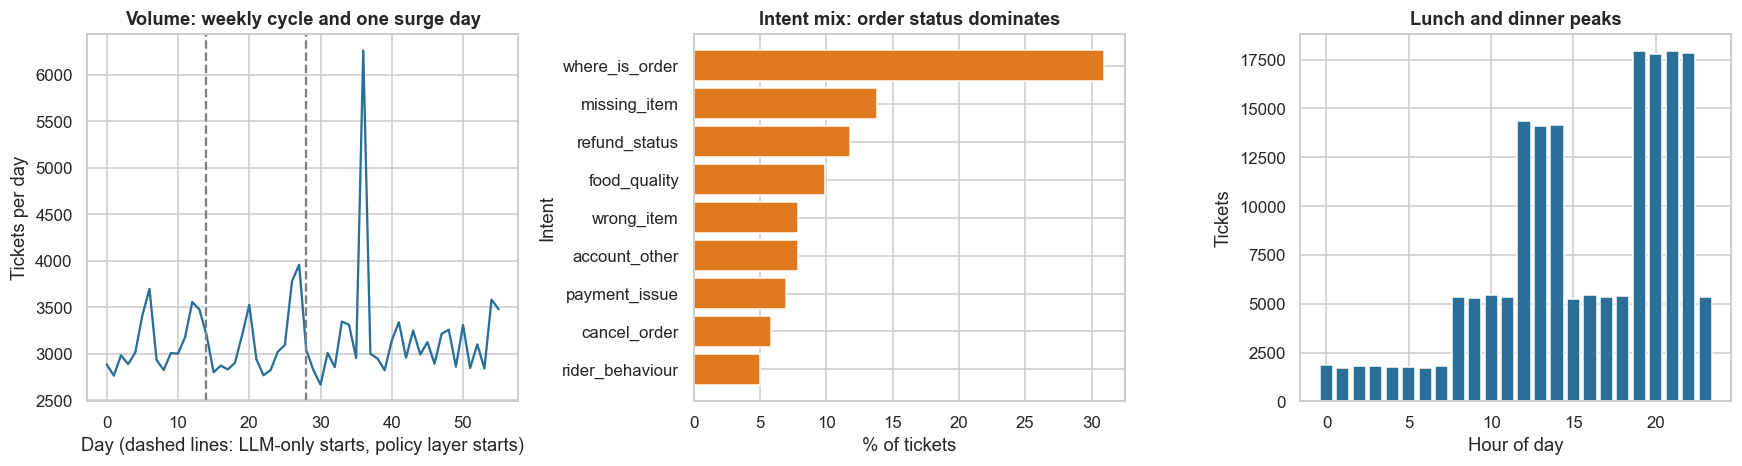

Surge day volume = 6,264 vs median day 3,008; hidden truth: 23.5% of tickets need a human, 0.70% are safety issues, 1.19% are abusive refund requests


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
vol = df.groupby("day").size(); axes[0].plot(vol.index, vol.values, color="#2a6f97"); axes[0].axvline(14, color="grey", ls="--"); axes[0].axvline(28, color="grey", ls="--"); axes[0].set_xlabel("Day (dashed lines: LLM-only starts, policy layer starts)"); axes[0].set_ylabel("Tickets per day"); axes[0].set_title("Volume: weekly cycle and one surge day")
im = df.intent.value_counts(normalize=True).sort_values(); axes[1].barh(im.index, im.values * 100, color="#e07a1f"); axes[1].set_xlabel("% of tickets"); axes[1].set_ylabel("Intent"); axes[1].set_title("Intent mix: order status dominates")
hr = df.groupby("hour").size(); axes[2].bar(hr.index, hr.values, color="#2a6f97"); axes[2].set_xlabel("Hour of day"); axes[2].set_ylabel("Tickets"); axes[2].set_title("Lunch and dinner peaks")
plt.tight_layout(); plt.show()
print(f"Surge day volume = {vol.loc[36]:,} vs median day {vol.median():,.0f}; hidden truth: {df._needs_human.mean():.1%} of tickets need a human, {df._safety.mean():.2%} are safety issues, {df._abuse.mean():.2%} are abusive refund requests")

**Takeaway:** volume has a weekly cycle and a **surge day with 6,264 tickets against a median day of 3,008**, with lunch and dinner peaks. Order-status questions dominate the intent mix, so a bot can plausibly take a large share. Hidden truth: **23.5% of tickets need a human**, 0.70% are safety issues and 1.19% are abusive refund requests, so the ceiling for safe containment is far below 100%.

## 7. Statistical Analysis (core section)

### 7.1 What does "containment" really measure? A funnel of definitions

**(a) Why?** "Containment" can mean three things: (1) **naive**: the bot was the last handler, (2) **proxy** (what we can observe): the bot was the last handler, the customer did not abandon, and did not re-contact within 72 hours, (3) **true** (simulation truth): the bot handler actually resolved the issue. The gap between them is the hidden cost of chasing containment. We use the bot pipeline (excluding the randomised holdout) in each phase and Wilson 95% CIs.

#### Code

In [7]:
def wil(k, n): lo, hi = proportion_confint(k, n, method="wilson"); return lo, hi
rows = []
for g_, d_ in df[df.arm == "bot_pipeline"].groupby("group"):
    n_ = len(d_); proxy = d_.cont & (d_.abandoned == 0) & (d_.recontact_72h == 0); truth = d_.cont & (d_._resolved == 1)
    lo, hi = wil(int(d_.cont.sum()), n_)
    rows.append((g_, n_, d_.cont.mean(), lo, hi, proxy.mean(), truth.mean(), d_[d_.cont].abandoned.mean(), d_[d_.cont].recontact_72h.mean(), d_.over_cont.mean(), d_._resolved.mean()))
fun = pd.DataFrame(rows, columns=["phase", "tickets", "naive containment", "CI low", "CI high", "proxy containment", "true containment", "abandon rate (of bot-kept)", "re-contact rate (of bot-kept)", "over-containment (kept but needed human)", "all-ticket resolution rate"]).set_index("phase")
fun.round(4)

,tickets,naive containment,CI low,CI high,proxy containment,true containment,abandon rate (of bot-kept),re-contact rate (of bot-kept),over-containment (kept but needed human),all-ticket resolution rate
phase,,,,,,,,,,
L legacy tree,43618,0.5951,0.5904,0.5997,0.4719,0.4712,0.1125,0.1674,0.0901,0.8476
M LLM-only,43726,0.7147,0.7104,0.7189,0.6072,0.6157,0.0752,0.1239,0.0878,0.8814
P LLM + policy,84769,0.6898,0.6867,0.6929,0.5951,0.6076,0.0657,0.1138,0.0646,0.8960


**Observation:** naive containment is **59.5% (legacy), 71.5% (LLM-only) and 69.0% (policy layer, CI 68.7% to 69.3%)**. Proxy containment is lower (47.2%, 60.7%, 59.5%) and true containment is 47.1%, 61.6% and 60.8%. The gap between naive and true is about **8 to 12 points**. Of tickets kept by the bot in the policy regime **6.6% were abandoned and 11.4% re-contacted**, and **6.5% of all tickets needed a human but stayed with the bot** (9.0% legacy, 8.8% LLM-only). The all-ticket resolution rate rose from 84.8% to 88.1% to 89.6%. The observable proxy tracks the true value closely here (59.5% vs 60.8%), but that depends on our simulated re-contact behaviour.

### 7.2 Why did containment swing? Daily volatility under LLM-only escalation vs the policy layer

**(a) Why?** The documented problem is that daily containment swung widely when the LLM alone decided escalations. We compute containment per day, then test whether the **variance** differs between the LLM-only days (14-27) and the policy-layer days (28-55): **Levene** (median-centred, robust to non-normality), the **F ratio** of variances, and a **bootstrap CI** for the SD ratio (resample days within each phase). A regression of daily containment on the daily intent mix and lateness checks whether ordinary mix shifts explain the swings.

**(b) Assumptions:** days are the unit (n = 14 and 28); daily rates are roughly independent after removing the weekly cycle, which is checked with the lag-1 autocorrelation.

#### Code

Phase 1 (LLM-only): mean 71.1%, SD 12.6 pp, range 51.3% to 88.9%
Phase 2 (policy)  : mean 68.9%, SD 2.2 pp, range 64.4% to 71.7%
Levene (median) W = 34.2, p = 7.7e-07 | F = 33.7, p = 5.5e-13 | SD ratio = 5.8 (bootstrap 95% CI 3.9 to 7.7)
Phase 1: R² of daily containment on intent mix + lateness = 0.10 | lag-1 autocorrelation of daily containment = +0.14
Phase 2: R² of daily containment on intent mix + lateness = 0.28 | lag-1 autocorrelation of daily containment = -0.19


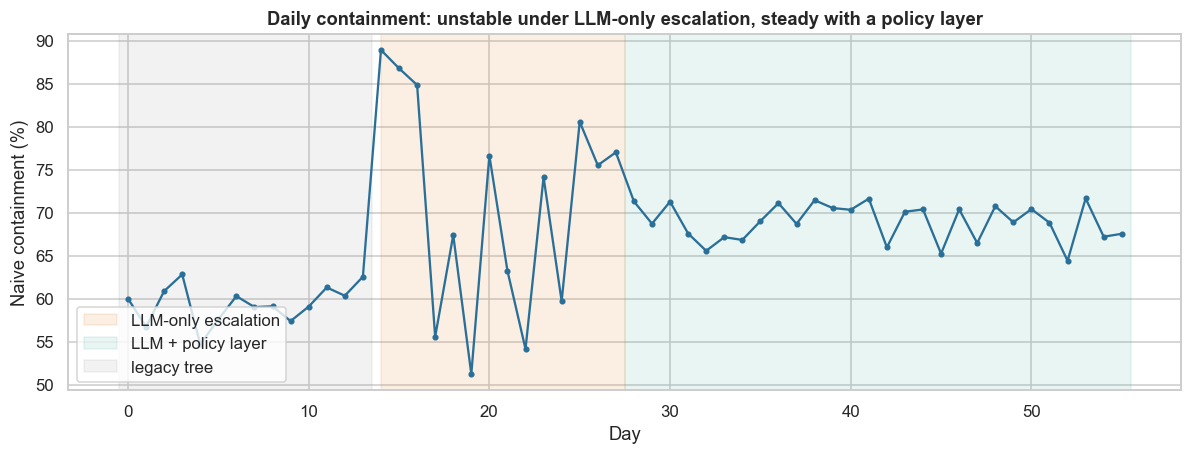

In [8]:
dc = pipe.groupby("day").agg(cont=("cont", "mean"), n=("cont", "size"), where_share=("intent", lambda s: (s == "where_is_order").mean()), late=("late_min", "mean"), phase=("phase", "first"))
a, b = dc[dc.phase == 1].cont.values, dc[dc.phase == 2].cont.values
lev = stats.levene(a, b, center="median"); F = a.var(ddof=1) / b.var(ddof=1); pF = 2 * min(stats.f.cdf(F, len(a) - 1, len(b) - 1), stats.f.sf(F, len(a) - 1, len(b) - 1))
bs = [np.std(RNG.choice(a, len(a)), ddof=1) / np.std(RNG.choice(b, len(b)), ddof=1) for _ in range(5000)]
print(f"Phase 1 (LLM-only): mean {a.mean():.1%}, SD {a.std(ddof=1) * 100:.1f} pp, range {a.min():.1%} to {a.max():.1%}")
print(f"Phase 2 (policy)  : mean {b.mean():.1%}, SD {b.std(ddof=1) * 100:.1f} pp, range {b.min():.1%} to {b.max():.1%}")
print(f"Levene (median) W = {lev.statistic:.1f}, p = {lev.pvalue:.2g} | F = {F:.1f}, p = {pF:.2g} | SD ratio = {np.std(a, ddof=1) / np.std(b, ddof=1):.1f} (bootstrap 95% CI {np.percentile(bs, 2.5):.1f} to {np.percentile(bs, 97.5):.1f})")
for ph in (1, 2):
    s = dc[dc.phase == ph]; m = smf.ols("cont ~ where_share + late", data=s).fit(); print(f"Phase {ph}: R² of daily containment on intent mix + lateness = {m.rsquared:.2f} | lag-1 autocorrelation of daily containment = {s.cont.autocorr(1):+.2f}")
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(dc.index, dc.cont * 100, color="#2a6f97", marker="o", ms=3); ax.axvspan(14, 27.5, color="#e07a1f", alpha=0.12, label="LLM-only escalation"); ax.axvspan(27.5, 55.5, color="#2a9d8f", alpha=0.10, label="LLM + policy layer"); ax.axvspan(-0.5, 13.5, color="grey", alpha=0.10, label="legacy tree")
ax.set_xlabel("Day"); ax.set_ylabel("Naive containment (%)"); ax.set_title("Daily containment: unstable under LLM-only escalation, steady with a policy layer"); ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

**Takeaway:** under LLM-only escalation daily containment averaged 71.1% with an **SD of 12.6 points and a range of 51.3% to 88.9%**, close to the documented 50% to 80% pattern. With the policy layer it averaged 68.9% with an **SD of 2.2 points (64.4% to 71.7%)**. The variance difference is clear (Levene p = 7.7e-07, F test p = 5.5e-13, SD ratio 5.8, bootstrap CI 3.9 to 7.7). Intent mix and lateness explain only 10% of the LLM-only variance (R² 0.10), so ordinary mix shifts do not explain the swings. The policy layer cost about 2.5 points of mean containment (71.1% to 68.9% by day), which is the price of stability. The lag-1 autocorrelation is small (+0.14 and -0.19), so treating days as independent is reasonable.

### 7.3 Did CSAT improve? Before/after vs the randomised holdout, with non-response

**(a) Why?** CSAT comes from a survey that only about one customer in eight answers, and who answers depends on the experience (unhappy and human-handled customers respond more; customers who abandon rarely do). We report **top-2-box** (share of 4 or 5 out of 5) among responders with Wilson CIs, **satisfied customers per 100 tickets** (which includes non-response) and an **inverse-probability-weighted (IPW)** top-2-box using observable predictors of response (intent, handler, abandonment, peak, group). Tests: two-proportion z-tests of P vs L and P vs H, a risk ratio with a log-method CI, and Cohen's h.

**(b) Assumptions and limits:** IPW removes bias from response differences explained by the observables; non-response driven by the unseen feeling cannot be fixed. L, M and P are different periods, so before/after contrasts are confounded by time; only P vs H is randomised.

#### Code

                       tickets  response rate  mean CSAT  top-2-box (responders)  CI low  CI high  satisfied per 100 tickets  top-2-box (IPW)
group                                                                                                                                        
L legacy tree            43618         0.1299     3.4756                  0.5322  0.5192   0.5452                     6.9146           0.5200
M LLM-only               43726         0.1292     3.6221                  0.5888  0.5760   0.6016                     7.6087           0.5875
P LLM + policy           84769         0.1284     3.6379                  0.5936  0.5843   0.6028                     7.6242           0.5958
H human-first holdout     4459         0.1691     3.3793                  0.4814  0.4460   0.5171                     8.1408           0.4821

          Δ top-2-box  p (z-test)  risk ratio  RR CI low  RR CI high  Cohen's h
contrast                                                           

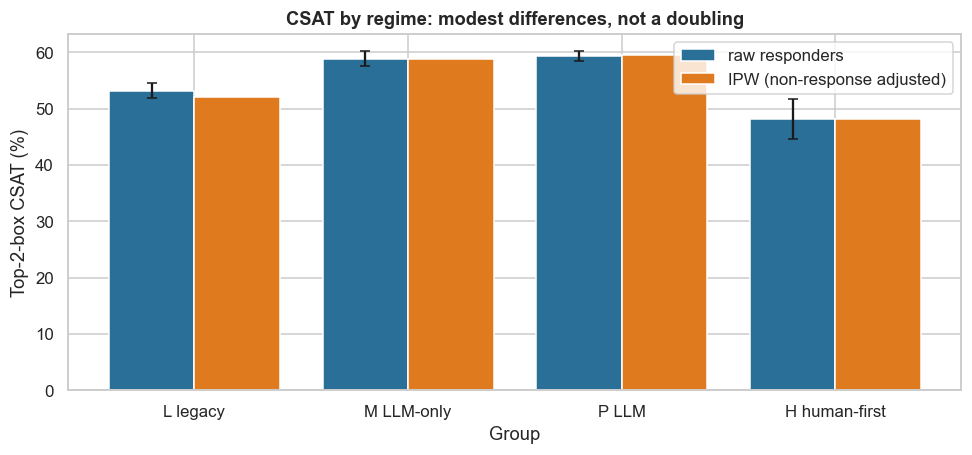

In [9]:
resp = df.csat.notna().astype(int)
lr = smf.logit("resp ~ C(intent) + C(handled_by) + abandoned + peak_hour + C(group)", data=df.assign(resp=resp)).fit(disp=0)
df["w"] = np.where(resp == 1, 1 / lr.predict(df), 0.0)
rows = []; order_g = ["L legacy tree", "M LLM-only", "P LLM + policy", "H human-first holdout"]
for g_ in order_g:
    d_ = df[df.group == g_]; r_ = d_[d_.csat.notna()]; lo, hi = wil(int(r_.top2.sum()), len(r_))
    rows.append((g_, len(d_), len(r_) / len(d_), r_.csat.mean(), r_.top2.mean(), lo, hi, r_.top2.sum() / len(d_) * 100, np.average(r_.top2, weights=r_.w)))
cs = pd.DataFrame(rows, columns=["group", "tickets", "response rate", "mean CSAT", "top-2-box (responders)", "CI low", "CI high", "satisfied per 100 tickets", "top-2-box (IPW)"]).set_index("group")
def ztwo(g1, g2):
    r1, r2 = df[(df.group == g1) & df.csat.notna()], df[(df.group == g2) & df.csat.notna()]; k = np.array([r1.top2.sum(), r2.top2.sum()]); n = np.array([len(r1), len(r2)])
    z, p = proportions_ztest(k, n); p1, p2 = k / n; rr = p1 / p2; se = np.sqrt((1 - p1) / k[0] + (1 - p2) / k[1]); h = proportion_effectsize(p1, p2)
    return (f"{g1[0]} vs {g2[0]}", p1 - p2, p, rr, rr * np.exp(-1.96 * se), rr * np.exp(1.96 * se), h)
ct = pd.DataFrame([ztwo("P LLM + policy", "L legacy tree"), ztwo("M LLM-only", "L legacy tree"), ztwo("P LLM + policy", "H human-first holdout")], columns=["contrast", "Δ top-2-box", "p (z-test)", "risk ratio", "RR CI low", "RR CI high", "Cohen's h"]).set_index("contrast")
print(cs.round(4).to_string()); print(); print(ct.round(4).to_string())
print(f"\nSatisfied per 100 tickets, P vs L: {cs.loc['P LLM + policy', 'satisfied per 100 tickets'] / cs.loc['L legacy tree', 'satisfied per 100 tickets']:.2f}x")
fig, ax = plt.subplots(figsize=(9, 4.3)); x = np.arange(len(order_g))
ax.bar(x - 0.2, cs["top-2-box (responders)"] * 100, 0.4, yerr=[(cs["top-2-box (responders)"] - cs["CI low"]) * 100, (cs["CI high"] - cs["top-2-box (responders)"]) * 100], color="#2a6f97", capsize=3, label="raw responders")
ax.bar(x + 0.2, cs["top-2-box (IPW)"] * 100, 0.4, color="#e07a1f", label="IPW (non-response adjusted)")
ax.set_xticks(x); ax.set_xticklabels([g.split(" ")[0] + " " + g.split(" ")[1] for g in order_g]); ax.set_xlabel("Group"); ax.set_ylabel("Top-2-box CSAT (%)"); ax.set_title("CSAT by regime: modest differences, not a doubling"); ax.legend(); plt.tight_layout(); plt.show()

**Takeaway:** top-2-box CSAT among responders is **53.2% for the legacy tree, 58.9% for LLM-only, 59.4% for the policy layer and 48.1% for the human-first holdout**. Policy vs legacy is +6.1 points (risk ratio 1.12, CI 1.08 to 1.15, Cohen's h 0.12, p < 1e-4), a small effect, not the documented "2x". Non-response weighting changes little (52.0%, 58.8%, 59.6%, 48.2%). The survey answers per 100 tickets rise only 1.10 times from legacy to policy, and the holdout actually has a **higher answer rate (16.9% vs 12.8%)** and 8.1 satisfied answers per 100 tickets against 7.6 for the policy layer. So the CSAT picture depends on whether non-response is counted. The L vs P comparison also confounds time and system; only P vs H is randomised.

### 7.4 The randomised holdout: bot pipeline vs human-first (intention to treat)

**(a) Why?** In phase 2, 5% of tickets were randomly sent to humans first. This is the only clean causal comparison: the **bot pipeline** (bot, with escalation when needed) vs **human-first**, both analysed as randomised (intention to treat). First we check **randomisation** with standardised mean differences (SMD below 0.1 is balanced) and a chi-square on the intent mix; then compare true resolution, the observable no-re-contact rate, first response time and IPW top-2-box (bootstrap CI).

#### Code

In [10]:
p2 = df[df.phase == 2]; Pp, Hh = p2[p2.arm == "bot_pipeline"], p2[p2.arm == "human_first"]
cov_ = ["order_value_inr", "late_min", "prior_refund_ratio", "tenure_orders", "chat_turns", "sentiment", "llm_escalation_score", "peak_hour", "_needs_human"]
smd = pd.Series({c: (Pp[c].mean() - Hh[c].mean()) / np.sqrt((Pp[c].var() + Hh[c].var()) / 2) for c in cov_}, name="SMD (bot pipeline - holdout)")
chi_int = stats.chi2_contingency(pd.crosstab(p2.arm, p2.intent))
print(f"Tickets: bot pipeline {len(Pp):,} | human-first {len(Hh):,} | max |SMD| = {smd.abs().max():.3f} | intent-mix chi-square p = {chi_int[1]:.2f}")
def two(k1, n1, k2, n2):
    p1, p2_ = k1 / n1, k2 / n2; se = np.sqrt(p1 * (1 - p1) / n1 + p2_ * (1 - p2_) / n2); return p1 - p2_, p1 - p2_ - 1.96 * se, p1 - p2_ + 1.96 * se, proportions_ztest([k1, k2], [n1, n2])[1]
rows = []
for nm, col in (("true resolution (hidden truth)", "_resolved"), ("no re-contact within 72 h (observable)", None)):
    s1 = Pp._resolved if col else (1 - Pp.recontact_72h); s2 = Hh._resolved if col else (1 - Hh.recontact_72h)
    rows.append((nm, s1.mean(), s2.mean(), *two(int(s1.sum()), len(s1), int(s2.sum()), len(s2))))
rP, rH = Pp[Pp.csat.notna()], Hh[Hh.csat.notna()]
dIPW = np.average(rP.top2, weights=rP.w) - np.average(rH.top2, weights=rH.w)
bsI = [np.average(x.top2, weights=x.w) - np.average(y.top2, weights=y.w) for x, y in ((rP.iloc[RNG.integers(0, len(rP), len(rP))], rH.iloc[RNG.integers(0, len(rH), len(rH))]) for _ in range(1000))]
rows.append(("top-2-box CSAT, IPW (responders)", np.average(rP.top2, weights=rP.w), np.average(rH.top2, weights=rH.w), dIPW, np.percentile(bsI, 2.5), np.percentile(bsI, 97.5), np.nan))
itt = pd.DataFrame(rows, columns=["outcome", "bot pipeline", "human-first", "difference", "CI low", "CI high", "p"]).set_index("outcome")
mw = stats.mannwhitneyu(Pp.first_response_s, Hh.first_response_s)
print(f"First response: median {Pp.first_response_s.median():.1f}s (bot pipeline) vs {Hh.first_response_s.median():.1f}s (human-first), Mann-Whitney p = {mw.pvalue:.2g}")
print(f"Responders: {len(rP):,} (pipeline) vs {len(rH):,} (holdout)"); print(smd.round(3).to_string()); itt.round(4)

Tickets: bot pipeline 84,769 | human-first 4,459 | max |SMD| = 0.024 | intent-mix chi-square p = 0.85


First response: median 7.8s (bot pipeline) vs 327.7s (human-first), Mann-Whitney p = 0
Responders: 10,888 (pipeline) vs 754 (holdout)
order_value_inr         0.0210
late_min                0.0090
prior_refund_ratio     -0.0170
tenure_orders           0.0240
chat_turns             -0.0170
sentiment              -0.0080
llm_escalation_score   -0.0200
peak_hour              -0.0010
_needs_human           -0.0130


,bot pipeline,human-first,difference,CI low,CI high,p
outcome,,,,,,
true resolution (hidden truth),0.8960,0.9262,-0.0302,-0.0382,-0.0223,0.0000
no re-contact within 72 h (observable),0.8983,0.9193,-0.0209,-0.0292,-0.0127,0.0000
"top-2-box CSAT, IPW (responders)",0.5958,0.4821,0.1137,0.0796,0.1505,NaN


**Observation:** randomisation looks sound: the largest standardised mean difference is **0.024** and the intent-mix chi-square p is 0.85. The bot pipeline has **lower true resolution than human-first: 89.6% vs 92.6% (difference -3.0 pp, CI -3.8 to -2.2)** and a lower observable no-re-contact rate (89.8% vs 91.9%). On the other hand its first response is far faster (**median 7.8 s vs 327.7 s**), and its non-response-weighted top-2-box is **59.6% vs 48.2% (+11.4 pp, CI 8.0 to 15.1)**. So customers prefer the bot's speed even though it resolves slightly fewer problems. The CSAT contrast uses only 754 holdout responders and weights cannot remove unseen non-response bias.

#### Per intent (Holm over nine intents)

Resolution differences per intent, with Wald CIs and Holm-adjusted p-values. CSAT per intent is not tested because the holdout has too few survey responders.

#### Code

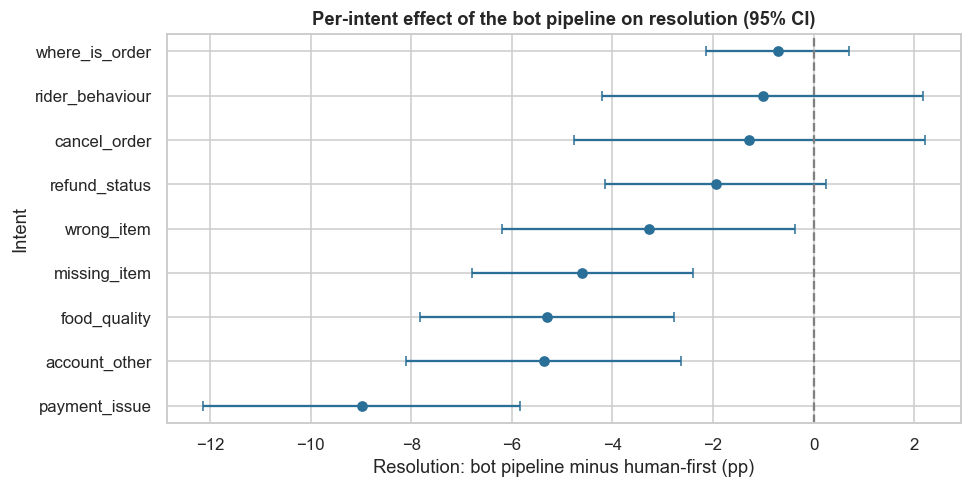

,holdout n,bot pipeline,human-first,diff,CI low,CI high,p,bot containment,p_holm
intent,,,,,,,,,
payment_issue,300,0.8334,0.9233,-0.0899,-0.1215,-0.0583,0.0000,0.5722,0.0003
account_other,361,0.8770,0.9307,-0.0537,-0.0811,-0.0263,0.0022,0.7010,0.0135
food_quality,426,0.8765,0.9296,-0.0530,-0.0783,-0.0277,0.0011,0.6047,0.0074
missing_item,597,0.8786,0.9246,-0.0460,-0.0680,-0.0240,0.0007,0.6815,0.0057
wrong_item,372,0.8839,0.9167,-0.0328,-0.0619,-0.0037,0.0531,0.6849,0.2655
refund_status,518,0.9149,0.9344,-0.0195,-0.0415,0.0025,0.1194,0.7875,0.4775
cancel_order,241,0.9084,0.9212,-0.0128,-0.0477,0.0222,0.5013,0.7878,1.0000
rider_behaviour,229,0.9287,0.9389,-0.0101,-0.0421,0.0218,0.5600,0.0000,1.0000
where_is_order,1415,0.9165,0.9237,-0.0072,-0.0214,0.0071,0.3415,0.7985,1.0000


In [11]:
rows = []
for it, d_ in p2.groupby("intent"):
    x, y = d_[d_.arm == "bot_pipeline"], d_[d_.arm == "human_first"]; diff, lo, hi, p = two(int(x._resolved.sum()), len(x), int(y._resolved.sum()), len(y)); rows.append((it, len(y), x._resolved.mean(), y._resolved.mean(), diff, lo, hi, p, x.cont.mean()))
pi = pd.DataFrame(rows, columns=["intent", "holdout n", "bot pipeline", "human-first", "diff", "CI low", "CI high", "p", "bot containment"]).set_index("intent"); pi["p_holm"] = multipletests(pi.p, method="holm")[1]; pi = pi.sort_values("diff")
fig, ax = plt.subplots(figsize=(9, 4.6)); yy = np.arange(len(pi))
ax.errorbar(pi["diff"] * 100, yy, xerr=[(pi["diff"] - pi["CI low"]) * 100, (pi["CI high"] - pi["diff"]) * 100], fmt="o", color="#2a6f97", capsize=3); ax.axvline(0, color="grey", ls="--")
ax.set_yticks(yy); ax.set_yticklabels(pi.index); ax.set_xlabel("Resolution: bot pipeline minus human-first (pp)"); ax.set_ylabel("Intent"); ax.set_title("Per-intent effect of the bot pipeline on resolution (95% CI)"); plt.tight_layout(); plt.show()
pi.round(4)

**Takeaway:** the bot pipeline is worse than human-first for resolution mainly on **payment issues (-9.0 pp, Holm p = 0.0003)**, then **account issues (-5.4 pp, p = 0.014), food quality (-5.3 pp, p = 0.007) and missing items (-4.6 pp, p = 0.006)**. Wrong items are borderline (-3.3 pp, raw p = 0.053, Holm 0.27) and the other four intents show no clear difference, including **where is my order (-0.7 pp, CI -2.1 to +0.7)**, the largest group. Rider-behaviour tickets are always escalated, so the pipeline is effectively human there. The costly gaps sit where the bot keeps 57% to 70% of the tickets, so these intents are candidates for earlier escalation.

### 7.5 Latency: how much faster, and does speed explain CSAT?

**(a) Why?** The documented claim is a response time under 10 seconds. First response is highly skewed, so we report **median, p90 and p99** (bootstrap CI for the median), a **Mann-Whitney** test L vs M, peak vs off-peak ratios, and a **logistic regression** of top-2-box on the wait until the final handler responds (minutes), controlling for resolution and handler, to ask whether speed matters beyond resolution.

#### Code

Mann-Whitney M vs L (first response): p = 0 | mean first response 194s (L) -> 9s (P)
Logistic top-2-box: odds ratio per extra minute of waiting = 0.957 (95% CI 0.951 to 0.963), p = 2e-37; resolved odds ratio 53.8


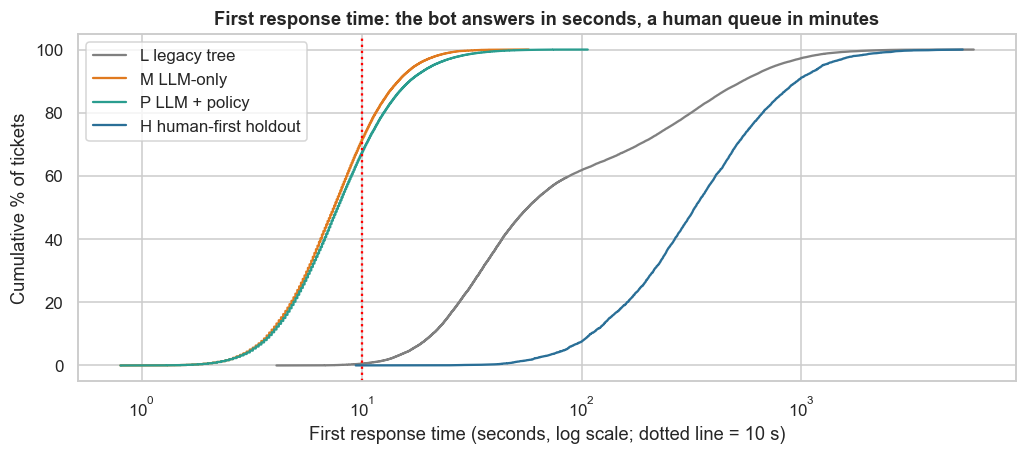

,median s,CI low,CI high,p90 s,p99 s,mean s,peak / off-peak median
group,,,,,,,
L legacy tree,57.1000,56.2000,57.8000,538.1300,"1,401.9100",193.5500,1.4400
M LLM-only,7.5000,7.4000,7.5000,14.7000,25.0800,8.5700,1.4000
P LLM + policy,7.8000,7.8000,7.8000,16.5000,34.3000,9.4400,1.3800
H human-first holdout,327.7000,318.9400,339.0200,956.4400,"2,282.1900",463.7000,2.3300


In [12]:
rows = []
for g_ in order_g:
    s = df[df.group == g_].first_response_s; bm = [np.median(RNG.choice(s.values, len(s))) for _ in range(300)]
    rows.append((g_, s.median(), np.percentile(bm, 2.5), np.percentile(bm, 97.5), s.quantile(0.9), s.quantile(0.99), s.mean(), df[(df.group == g_) & (df.peak_hour == 1)].first_response_s.median() / df[(df.group == g_) & (df.peak_hour == 0)].first_response_s.median()))
lat = pd.DataFrame(rows, columns=["group", "median s", "CI low", "CI high", "p90 s", "p99 s", "mean s", "peak / off-peak median"]).set_index("group")
ml_ = stats.mannwhitneyu(df[df.group == "M LLM-only"].first_response_s, df[df.group == "L legacy tree"].first_response_s)
rr_ = df[df.csat.notna()].assign(wait_min=lambda x: x.time_to_resolution_wait_s / 60)
lg = smf.logit("top2 ~ wait_min + _resolved + C(handled_by)", data=rr_).fit(disp=0)
print(f"Mann-Whitney M vs L (first response): p = {ml_.pvalue:.2g} | mean first response {df[df.group == 'L legacy tree'].first_response_s.mean():.0f}s (L) -> {df[df.group == 'P LLM + policy'].first_response_s.mean():.0f}s (P)")
print(f"Logistic top-2-box: odds ratio per extra minute of waiting = {np.exp(lg.params['wait_min']):.3f} (95% CI {np.exp(lg.conf_int().loc['wait_min', 0]):.3f} to {np.exp(lg.conf_int().loc['wait_min', 1]):.3f}), p = {lg.pvalues['wait_min']:.2g}; resolved odds ratio {np.exp(lg.params['_resolved']):.1f}")
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for g_, c_ in zip(order_g, ["grey", "#e07a1f", "#2a9d8f", "#2a6f97"]):
    s = np.sort(df[df.group == g_].first_response_s.values); ax.plot(s, np.arange(1, len(s) + 1) / len(s) * 100, label=g_, color=c_)
ax.set_xscale("log"); ax.axvline(10, color="red", ls=":"); ax.set_xlabel("First response time (seconds, log scale; dotted line = 10 s)"); ax.set_ylabel("Cumulative % of tickets"); ax.set_title("First response time: the bot answers in seconds, a human queue in minutes"); ax.legend(); plt.tight_layout(); plt.show()
lat.round(2)

**Takeaway:** first response is **57 s median for the legacy regime (which includes human-routed tickets), 7.5 s for LLM-only, 7.8 s for the policy layer and 328 s for the human-first holdout**. The policy layer's p90 is 16.5 s and its p99 is 34 s, so the sub-10-second target holds for the typical ticket but not for the tail. Peak hours slow every route (human-first peak median is 2.3 times off-peak, the bot 1.4 times). Waiting matters for CSAT: each extra minute lowers the odds of a 4 or 5 by about 4% (odds ratio 0.957, CI 0.951 to 0.963), while being resolved has an odds ratio of 54. Resolution matters far more than speed, but the bot's speed gives it a CSAT edge over human-first.

### 7.6 Over-containment and safety: where does the bot keep tickets it should not?

**(a) Why?** Over-containment (hidden truth: the ticket needed a human but the bot kept it) is the main hidden cost of high containment. We map it by intent and regime (heatmap), test whether the policy layer changed the **overall** rate (chi-square, risk ratio), and test the **safety** tickets separately (Fisher exact), because a missed safety complaint is a different kind of failure from a missed "where is my order". A logistic regression of 72-hour re-contact on over-containment (with intent and peak controls) shows what it costs.

#### Code

Over-containment, LLM-only vs policy: 8.78% vs 6.46% (RR 0.74), chi-square p = 2.8e-52
Safety tickets kept by the bot, LLM-only vs policy: Fisher exact p = 1.4e-37, odds ratio 0.08
                safety tickets  safety tickets kept by the bot  share kept
phase                                                                     
L legacy tree              283                               0      0.0000
M LLM-only                 319                             120      0.3760
P LLM + policy             600                              27      0.0450
Re-contact odds ratio for an over-contained ticket = 10.9 (95% CI 10.5 to 11.3)


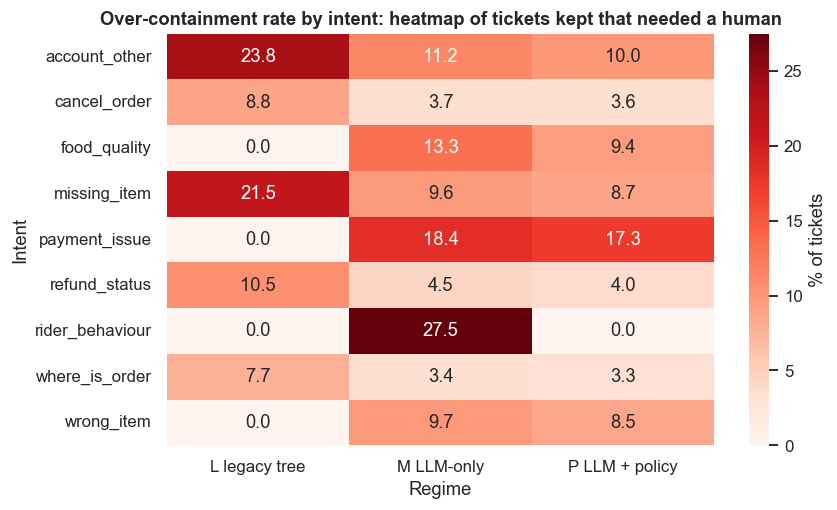

In [13]:
hm = pipe.pivot_table(index="intent", columns="group", values="over_cont", aggfunc="mean") * 100
tt = pipe[pipe.phase.isin([1, 2])]; ct2 = pd.crosstab(tt.phase, tt.over_cont); chi_oc = stats.chi2_contingency(ct2, correction=False); rr_oc = tt[tt.phase == 2].over_cont.mean() / tt[tt.phase == 1].over_cont.mean()
sf = pipe[(pipe._safety == 1) & pipe.phase.isin([1, 2])]; sft = pd.crosstab(sf.phase, sf.cont); fe = stats.fisher_exact(sft.values)
srows = [(g_, int(((d_._safety == 1)).sum()), int(((d_._safety == 1) & d_.cont).sum())) for g_, d_ in pipe.groupby("group")]
sfx = pd.DataFrame(srows, columns=["phase", "safety tickets", "safety tickets kept by the bot"]).set_index("phase"); sfx["share kept"] = sfx.iloc[:, 1] / sfx.iloc[:, 0]
lg2 = smf.logit("recontact_72h ~ over_cont + C(intent) + peak_hour", data=pipe).fit(disp=0)
print(f"Over-containment, LLM-only vs policy: {tt[tt.phase == 1].over_cont.mean():.2%} vs {tt[tt.phase == 2].over_cont.mean():.2%} (RR {rr_oc:.2f}), chi-square p = {chi_oc[1]:.2g}")
print(f"Safety tickets kept by the bot, LLM-only vs policy: Fisher exact p = {fe[1]:.2g}, odds ratio {fe[0]:.2f}"); print(sfx.round(3).to_string())
print(f"Re-contact odds ratio for an over-contained ticket = {np.exp(lg2.params['over_cont']):.1f} (95% CI {np.exp(lg2.conf_int().loc['over_cont', 0]):.1f} to {np.exp(lg2.conf_int().loc['over_cont', 1]):.1f})")
fig, ax = plt.subplots(figsize=(8, 4.8)); sns.heatmap(hm[["L legacy tree", "M LLM-only", "P LLM + policy"]], annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "% of tickets"}); ax.set_title("Over-containment rate by intent: heatmap of tickets kept that needed a human"); ax.set_xlabel("Regime"); ax.set_ylabel("Intent"); plt.tight_layout(); plt.show()

**Takeaway:** the heatmap shows over-containment concentrated in the intents where a human is more often needed. Overall, the policy layer cut over-containment from **8.78% to 6.46% (risk ratio 0.74, chi-square p < 1e-50)**. Safety tickets kept by the bot fell from **37.6% (120 of 319) to 4.5% (27 of 600)** (Fisher exact p = 1.4e-37, odds ratio 0.08); the legacy tree kept none because it only handles simple intents. The 27 remaining safety tickets are the 15% the keyword rule misses and are the main residual risk. A wrongly kept ticket is **10.9 times** as likely to produce a re-contact (CI 10.5 to 11.3).

### 7.7 Refund abuse: leakage under LLM-only decisions vs the policy layer

**(a) Why?** LLM-only agents tend to trust the customer's story. Among abusive refund requests (hidden truth) we compare the **approval rate** and the **₹ leaked** per 1,000 refund tickets across regimes, test LLM-only vs policy with a chi-square, and measure the **friction** on legitimate refund requests (share escalated to a human or denied).

#### Code

In [14]:
rf = pipe[pipe.refund_requested == 1]; rows = []
for g_, d_ in rf.groupby("group"):
    ab, lg_ = d_[d_._abuse == 1], d_[d_._abuse == 0]
    rows.append((g_, len(d_), len(ab), ab.refund_approved.mean(), d_._leak_inr.sum() / len(d_) * 1000, lg_.cont.mean(), (lg_.refund_approved == 0).mean(), (~lg_.cont | (lg_.refund_approved == 0)).mean()))
lk = pd.DataFrame(rows, columns=["phase", "refund tickets", "abusive requests", "approval rate of abusive", "₹ leaked per 1,000 refund tickets", "legit tickets kept by bot", "legit tickets denied", "legit friction (escalated or denied)"]).set_index("phase")
a1, a2 = rf[(rf._abuse == 1) & (rf.phase == 1)], rf[(rf._abuse == 1) & (rf.phase == 2)]
ch = stats.chi2_contingency(np.array([[a1.refund_approved.sum(), len(a1) - a1.refund_approved.sum()], [a2.refund_approved.sum(), len(a2) - a2.refund_approved.sum()]]), correction=False)
print(f"Abusive-request approval, LLM-only vs policy: {a1.refund_approved.mean():.1%} (n = {len(a1)}) vs {a2.refund_approved.mean():.1%} (n = {len(a2)}), chi-square p = {ch[1]:.2g}")
print(f"Abuse score separates abuse: AUC = {roc_auc_score(rf._abuse, rf.abuse_score):.3f}")
lk.round(3)

Abusive-request approval, LLM-only vs policy: 74.7% (n = 518) vs 43.0% (n = 1022), chi-square p = 3.6e-32
Abuse score separates abuse: AUC = 0.970


,refund tickets,abusive requests,approval rate of abusive,"₹ leaked per 1,000 refund tickets",legit tickets kept by bot,legit tickets denied,legit friction (escalated or denied)
phase,,,,,,,
L legacy tree,13934,507,0.4710,"5,365.4370",0.3730,0.0710,0.6380
M LLM-only,13854,518,0.7470,"8,268.8750",0.6900,0.0700,0.3480
P LLM + policy,26590,1022,0.4300,"4,912.3730",0.6780,0.0320,0.3220


**Observation:** LLM-only decisions approved **74.7% of abusive refund requests** (n = 518), against **43.0%** (n = 1,022) with the policy layer (chi-square p = 3.6e-32); the legacy rule approved 47.1%. Leakage per 1,000 refund tickets was **₹8,269 under LLM-only, ₹4,912 with the policy layer** and ₹5,365 for the legacy tree. The abuse score separates abuse well (AUC 0.970). Friction for legitimate requests (escalated or denied) was **34.8% under LLM-only and 32.2% with policy**, so stricter rules did not obviously cost legitimate customers more, but the policy layer denies fewer legitimate requests (3.2% vs 7.0%) mainly because humans handle more of them.

### 7.8 Power and design: how big must a holdout be, and how many days to trust a volatility estimate?

**(a) Why?** Without a holdout we cannot measure CSAT effects; with a small one we may miss them. We compute the **minimum detectable effect** for true resolution and top-2-box CSAT at our holdout size (80% power, two-sided 5%), the **sample sizes** needed for a 3-point CSAT effect, and how precisely a **standard deviation of daily containment** can be estimated from n days (chi-square CI), since the stability claim rests on 14 and 28 days.

#### Code

In [15]:
pw = NormalIndPower(); nP, nH = len(Pp), len(Hh)
res_h, cs_h = Hh._resolved.mean(), rH.top2.mean(); eff_res = pw.solve_power(effect_size=None, nobs1=nH, alpha=0.05, power=0.8, ratio=nP / nH); eff_cs = pw.solve_power(effect_size=None, nobs1=len(rH), alpha=0.05, power=0.8, ratio=len(rP) / len(rH))
print(f"Holdout n = {nH:,} tickets, {len(rH)} survey responders. Minimum detectable effect (Cohen's h): resolution {eff_res:.3f} (about {eff_res * 2 * np.sqrt(res_h * (1 - res_h)) * 100:.1f} pp near {res_h:.0%}), CSAT top-2-box {eff_cs:.3f} (about {eff_cs * 2 * np.sqrt(cs_h * (1 - cs_h)) * 100:.1f} pp near {cs_h:.0%})")
rr_resp = df.csat.notna().mean(); rows = []
for d_pp in (0.02, 0.03, 0.05):
    h = proportion_effectsize(cs_h + d_pp, cs_h); n_r = int(np.ceil(pw.solve_power(effect_size=h, alpha=0.05, power=0.8))); rows.append((f"{d_pp * 100:.0f} pp CSAT effect", n_r, int(np.ceil(n_r / rr_resp))))
pwt = pd.DataFrame(rows, columns=["effect to detect", "responders per arm", "tickets per arm (at observed response rate)"]).set_index("effect to detect")
sd_rows = [(nd, np.sqrt((nd - 1) / stats.chi2.ppf(0.975, nd - 1)), np.sqrt((nd - 1) / stats.chi2.ppf(0.025, nd - 1))) for nd in (7, 14, 28, 56)]
sdt = pd.DataFrame(sd_rows, columns=["days observed", "SD CI low (x estimate)", "SD CI high (x estimate)"]).set_index("days observed")
print(pwt.to_string()); sdt.round(2)

Holdout n = 4,459 tickets, 754 survey responders. Minimum detectable effect (Cohen's h): resolution 0.043 (about 2.3 pp near 93%), CSAT top-2-box 0.106 (about 10.5 pp near 48%)
                  responders per arm  tickets per arm (at observed response rate)
effect to detect                                                                 
2 pp CSAT effect                9807                                        75424
3 pp CSAT effect                4359                                        33524
5 pp CSAT effect                1569                                        12067


,SD CI low (x estimate),SD CI high (x estimate)
days observed,,
7,0.6400,2.2000
14,0.7200,1.6100
28,0.7900,1.3600
56,0.8400,1.2300


**Observation:** the holdout (4,459 tickets) can detect a **2.3 pp difference in true resolution** at 80% power, which is why the -3.0 pp result is credible. The holdout has only 754 survey responders and can only detect a CSAT difference of about **10.5 pp**, so per-intent CSAT is out of reach. A 3 pp CSAT effect needs **4,359 responders per arm, about 33,500 tickets per arm** at a 13% response rate. A standard deviation estimated from 14 days has a CI from 0.72 to 1.61 times the estimate (28 days: 0.79 to 1.36), so the 12.6 vs 2.2 point contrast is far larger than the estimation error.

## 8. ML Section — predicting bot failure and setting the escalation threshold

The bot already escalates using the LLM score and the policy rules. Can a small model, trained only on **observable** features (intent, order and customer context, chat turns, sentiment, LLM score, abuse score, safety keyword), predict which **bot-kept** tickets will fail (the customer abandons or re-contacts within 72 hours), so that we can escalate the riskiest few percent earlier? Training uses days 14 to 41; testing uses days 42 to 55 (time-ordered). Gradient boosting (fixed defaults, **no tuning**) is compared with logistic regression. Escalated tickets are assumed to be handled by a human with the outcomes observed in the same period.

#### Code

In [16]:
feats = ["order_value_inr", "late_min", "prior_refund_ratio", "tenure_orders", "tickets_30d", "chat_turns", "sentiment", "llm_escalation_score", "abuse_score", "peak_hour", "hour", "safety_keyword"]
bk = pipe[pipe.cont & (pipe.phase >= 1)].copy(); bk["fail"] = ((bk.abandoned == 1) | (bk.recontact_72h == 1)).astype(int)
Xf = pd.concat([bk[feats], pd.get_dummies(bk.intent, prefix="i").astype(float)], axis=1); tr, te = (bk.day < 42).values, (bk.day >= 42).values
gb = HistGradientBoostingClassifier(random_state=SEED).fit(Xf[tr], bk.fail[tr]); lgm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xf[tr], bk.fail[tr])
pg, pl = gb.predict_proba(Xf[te])[:, 1], lgm.predict_proba(Xf[te])[:, 1]; yte = bk.fail[te].values
def auc_ci(y, p, B=300):
    v = [roc_auc_score(y[i], p[i]) for i in (RNG.integers(0, len(y), len(y)) for _ in range(B))]; return np.percentile(v, 2.5), np.percentile(v, 97.5)
mt = pd.DataFrame({"AUC": [roc_auc_score(yte, pg), roc_auc_score(yte, pl)], "AUC CI low": [auc_ci(yte, pg)[0], auc_ci(yte, pl)[0]], "AUC CI high": [auc_ci(yte, pg)[1], auc_ci(yte, pl)[1]], "Brier": [brier_score_loss(yte, pg), brier_score_loss(yte, pl)]}, index=["gradient boosting", "logistic regression"])
top = pg >= np.quantile(pg, 0.9)
print(f"Train {tr.sum():,} / test {te.sum():,} bot-kept tickets | failure rate train {bk.fail[tr].mean():.1%}, test {yte.mean():.1%} | base failure rate in top-10% risk {yte[top].mean():.1%} (lift {yte[top].mean() / yte.mean():.2f}x)")
mt.round(4)

Train 61,311 / test 28,415 bot-kept tickets | failure rate train 14.3%, test 14.0% | base failure rate in top-10% risk 37.2% (lift 2.65x)


,AUC,AUC CI low,AUC CI high,Brier
gradient boosting,0.6420,0.6315,0.6524,0.1129
logistic regression,0.6452,0.6361,0.6553,0.1134


**Observation:** the failure model is **weak: AUC 0.642 (CI 0.632 to 0.652) for gradient boosting and 0.645 (0.636 to 0.655) for logistic regression**, with no gain from the more complex model. The Brier scores are similar (0.113). Still, the riskiest 10% of bot-kept tickets fail **37.2% of the time against a base of 14.0% (lift 2.65 times)**, so even a modest model concentrates failures. Features are mostly the same ones that drive the LLM's own score, so little new signal is expected.

#### Escalation-threshold frontier

For the test days, take every bot-pipeline ticket. Escalate the top q% riskiest bot-kept tickets (by the model) to humans and compare with escalating the **same number at random**. Escalated tickets get the human outcomes seen in phase 2 (resolution, re-contact, refund approval of abusive requests). We track naive containment, all-ticket true resolution and ₹ cost per ticket (human ₹55, bot ₹4, re-contact costs one more human ticket, ₹120 margin lost per unresolved ticket, plus refund leakage; assumptions D-29-07).

#### Code

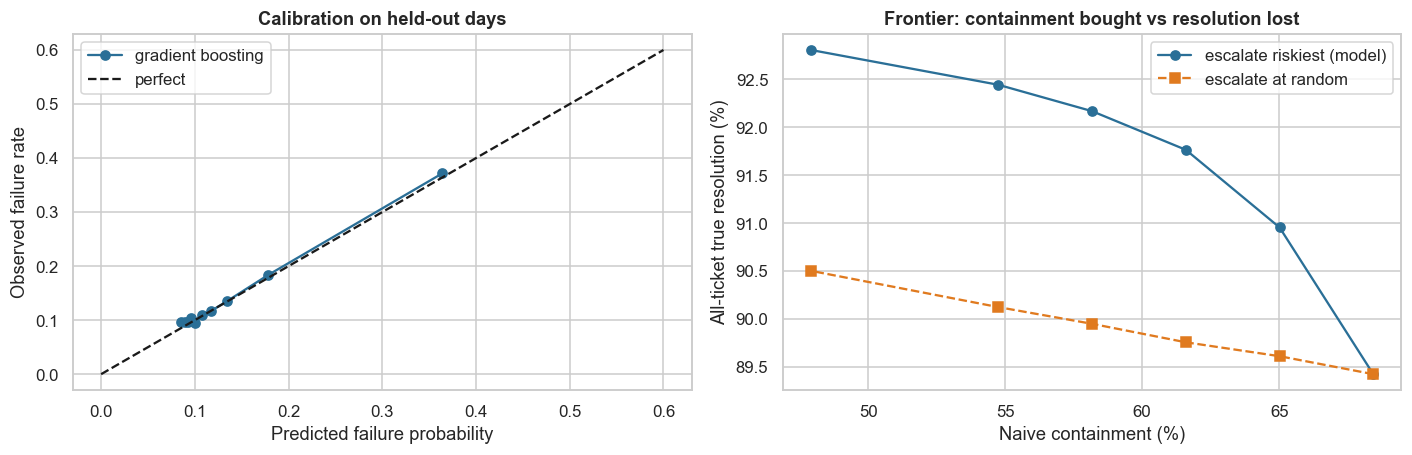

,containment (model),true resolution (model),cost/ticket ₹ (model),true resolution (random),cost/ticket ₹ (random)
escalate extra,,,,,
0.0000,0.6844,0.8942,39.9908,0.8942,39.9908
0.0500,0.6502,0.9095,39.2951,0.8961,41.4068
0.1000,0.6159,0.9176,39.7672,0.8976,42.8892
0.1500,0.5817,0.9217,40.8499,0.8995,44.3218
0.2000,0.5475,0.9244,42.1128,0.9012,45.7421
0.3000,0.4791,0.9281,44.9611,0.9050,48.5582


In [17]:
HC, BC, LOSS = 55.0, 4.0, 120.0
tp_ = pipe[pipe.day >= 42].copy(); tp_["p"] = np.nan; tp_.loc[tp_.cont, "p"] = gb.predict_proba(pd.concat([tp_.loc[tp_.cont, feats], pd.get_dummies(tp_.loc[tp_.cont, "intent"], prefix="i").astype(float)], axis=1).reindex(columns=Xf.columns, fill_value=0.0))[:, 1]
hum = pipe[(pipe.phase == 2) & ~pipe.cont]; h_res, h_rc = hum._resolved.mean(), hum.recontact_72h.mean(); APPR_ABUSE = 0.35
def econ(esc):
    N = len(tp_); kept = tp_.cont.values & ~esc; e_n = esc.sum(); res = tp_._resolved.values[kept].sum() + h_res * e_n + tp_._resolved.values[~tp_.cont.values].sum()
    rc = tp_.recontact_72h.values[kept].sum() + h_rc * e_n + tp_.recontact_72h.values[~tp_.cont.values].sum(); leak = tp_._leak_inr.values[kept | ~tp_.cont.values].sum() + (tp_._abuse.values * tp_.refund_inr.values * APPR_ABUSE)[esc].sum()
    bot, humn = kept.sum() / N, 1 - kept.sum() / N; cost = BC * bot + HC * (humn + rc / N) + LOSS * (1 - res / N) + leak / N
    return dict(containment=bot, true_resolution=res / N, recontact=rc / N, leak_per_ticket=leak / N, cost_per_ticket=cost)
fr = []; cidx = np.where(tp_.cont.values)[0]; ordr = cidx[np.argsort(-tp_.p.values[cidx])]
for q in (0, 0.05, 0.10, 0.15, 0.20, 0.30):
    k = int(q * len(cidx)); e = np.zeros(len(tp_), bool); e[ordr[:k]] = True
    m_ = econ(e); rnd = [econ(np.isin(np.arange(len(tp_)), RNG.choice(cidx, k, replace=False))) for _ in range(10)]
    fr.append({"escalate extra": q, "containment (model)": m_["containment"], "true resolution (model)": m_["true_resolution"], "cost/ticket ₹ (model)": m_["cost_per_ticket"], "true resolution (random)": np.mean([r["true_resolution"] for r in rnd]), "cost/ticket ₹ (random)": np.mean([r["cost_per_ticket"] for r in rnd])})
fr = pd.DataFrame(fr).set_index("escalate extra")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
cc, cp = calibration_curve(yte, pg, n_bins=10, strategy="quantile"); axes[0].plot(cp, cc, "o-", color="#2a6f97", label="gradient boosting"); axes[0].plot([0, 0.6], [0, 0.6], "k--", label="perfect"); axes[0].set_xlabel("Predicted failure probability"); axes[0].set_ylabel("Observed failure rate"); axes[0].set_title("Calibration on held-out days"); axes[0].legend()
axes[1].plot(fr["containment (model)"] * 100, fr["true resolution (model)"] * 100, "o-", color="#2a6f97", label="escalate riskiest (model)"); axes[1].plot(fr["containment (model)"] * 100, fr["true resolution (random)"] * 100, "s--", color="#e07a1f", label="escalate at random"); axes[1].set_xlabel("Naive containment (%)"); axes[1].set_ylabel("All-ticket true resolution (%)"); axes[1].set_title("Frontier: containment bought vs resolution lost"); axes[1].legend()
plt.tight_layout(); plt.show()
fr.round(4)

**Takeaway:** escalating the model's riskiest tickets beats escalating at random at every level. With **5% extra escalation, true resolution rises from 89.4% to 91.0% (random: 89.6%) and cost per ticket falls from ₹39.99 to ₹39.30 (random: ₹41.41)**. At 10% the resolution is 91.8% but cost is ₹39.77, at 20% it is ₹42.11 and at 30% ₹44.96, so extra escalation stops paying around 5% to 10%. Naive containment falls by about 3.4 points per 5% escalated (68.4% to 65.0%), which shows that containment and resolution pull in opposite directions at the margin. The frontier assumes escalated tickets get the human outcomes seen in phase 2 and ignores queue growth. The calibration panel is shown for transparency; the gradient boosting probabilities are used only to rank tickets.

## 9. Business Translation — ₹ impact

Assumptions (D-29-07): **1 crore support contacts a month** (the reference reports more than 1.5 crore conversations a month; we use a smaller round number), human-handled ticket ₹55, bot ticket ₹4, a re-contact costs one more human ticket, each unresolved ticket loses ₹120 of future margin, refund leakage as simulated. Scenarios change the human cost, the margin lost per unresolved ticket and the leakage multiplier. Baseline is the legacy tree. Rates come from each regime's bot-pipeline tickets; the "policy plus model" row applies the frontier's 10% extra escalation to the policy-layer regime.

#### Code

In [18]:
def rates(d_): return dict(bot=d_.cont.mean(), recon=d_.recontact_72h.mean(), unres=1 - d_._resolved.mean(), leak=d_._leak_inr.mean())
RT = {"legacy tree": rates(pipe[pipe.phase == 0]), "LLM-only": rates(pipe[pipe.phase == 1]), "LLM + policy layer": rates(pipe[pipe.phase == 2])}
b0, b10 = econ(np.zeros(len(tp_), bool)), econ(np.isin(np.arange(len(tp_)), ordr[:int(0.10 * len(cidx))]))
pp_ = RT["LLM + policy layer"]; dres = b10["true_resolution"] - b0["true_resolution"]; dleak = b10["leak_per_ticket"] - b0["leak_per_ticket"]; dbot = b10["containment"] - b0["containment"]; drc = b10["recontact"] - b0["recontact"]
RT["LLM + policy + model (10% extra)"] = dict(bot=pp_["bot"] + dbot, recon=pp_["recon"] + drc, unres=pp_["unres"] - dres, leak=pp_["leak"] + dleak)
SC = {"best": (80.0, 200.0, 1.0), "base": (55.0, 120.0, 1.0), "worst": (40.0, 60.0, 2.0)}
def cost(r, hc, loss, lm): return BC * r["bot"] + hc * (1 - r["bot"] + r["recon"]) + loss * r["unres"] + lm * r["leak"]
rows = {}
for nm, r in RT.items():
    rows[nm] = {"bot share": r["bot"], "unresolved share": r["unres"], "leak ₹/ticket": r["leak"], "cost ₹/ticket (base)": cost(r, *SC["base"])}
    for sc, prm in SC.items():
        if nm != "legacy tree": rows[nm][f"saving ₹ crore/year ({sc})"] = (cost(RT["legacy tree"], *prm) - cost(r, *prm)) * 12
money = pd.DataFrame(rows).T; print("Volume: 1 crore contacts a month = 12 crore a year; saving = (legacy cost − new cost) per ticket × 12 crore"); money.round(3)

Volume: 1 crore contacts a month = 12 crore a year; saving = (legacy cost − new cost) per ticket × 12 crore


,bot share,unresolved share,leak ₹/ticket,cost ₹/ticket (base),saving ₹ crore/year (best),saving ₹ crore/year (base),saving ₹ crore/year (worst)
legacy tree,0.5950,0.1520,1.7140,51.7390,NaN,NaN,NaN
LLM-only,0.7150,0.1190,2.6200,41.4320,197.7610,123.6730,63.4840
LLM + policy layer,0.6900,0.1040,1.5410,39.4310,230.7230,147.6880,92.9760
LLM + policy + model (10% extra),0.6210,0.0810,1.4560,39.2080,239.8220,150.3720,89.4570


**Takeaway (business reading):** against the legacy tree, the **policy layer saves about ₹148 crore a year in the base case (₹93 crore worst, ₹231 crore best)** and LLM-only saves ₹124 crore (₹63 crore to ₹198 crore). The policy layer is better in every scenario because it lowers unresolved tickets (10.4% vs 11.9%) and leakage (₹1.54 vs ₹2.62 per ticket), even though it keeps fewer tickets with the bot (69.0% vs 71.5%). Adding 10% extra model-based escalation adds only about ₹2.7 crore in the base case (₹150.4 crore) and **loses ₹3.5 crore in the worst case (₹89.5 crore)**, so it is not worth rolling out at 10%; the frontier points to about 5%. The level depends on assumed unit costs, so the ranking is more reliable than the rupee figure.

## 10. Recommendation and Decision

**Recommendation: keep the LLM plus policy-layer design, make true resolution the headline KPI, and keep a permanent 5% human-first holdout.**

| Decision | Rule | Evidence |
|---|---|---|
| Escalation design | Keep deterministic policy rules around the LLM | Daily containment SD 2.2 vs 12.6 points; safety tickets kept 4.5% vs 37.6%; abusive refunds approved 43% vs 75% |
| Human-first intents | Route payment issues, safety keywords and rider behaviour to humans; review account, food-quality and missing-item thresholds | Holdout resolution gaps of 4.6 to 9.0 pp (Holm p < 0.05) |
| Extra escalation | Pilot the failure model at about 5% extra escalation, in shadow mode first | True resolution 91.0% vs 89.6% at random; cost ₹39.3 vs ₹41.4; no gain at 10% in the worst case |
| Measurement | Report naive and true containment, holdout CSAT, first response and re-contact together | Naive 69.0% vs true 60.8%; CSAT effect +6 points, not 2x |

**Decision rule:** roll back or retune if the 14-day rolling SD of daily containment exceeds 5 points, if holdout resolution gap exceeds 5 pp overall, if any safety ticket is kept by the bot, or if the abusive-refund approval rate rises above 50%.

**KPIs:** true resolution rate (sampled human grading), naive containment, 72-hour re-contact, first response (median and p90), top-2-box CSAT with non-response weights and a holdout comparison, safety tickets kept by the bot (target zero), abusive-refund leakage in ₹, cost per ticket.

## 11. Risks, Limitations and Next Steps

- **Simulated truth:** the hidden labels (needs a human, abuse, safety, resolved) are assumed; in real data resolution is unobserved and must be estimated from re-contact, sampled human grading and LLM-as-judge on the four documented rubric metrics.
- **Survey bias:** only about one customer in eight answers the CSAT survey and non-response is not random. IPW fixes only what the observables explain; keep the randomised holdout and compare against it.
- **Holdout size:** 5% gave a precise resolution contrast but too few survey responders for per-intent CSAT. Plan the size for the outcome that matters.
- **Policy layer is a stabiliser, not a free gain:** here it lowered naive containment and added friction for some legitimate refund requests; tune its rules with cost data.
- **Escalated tickets:** the frontier assumes extra escalations get the human outcomes seen in the same period; a queue that grows with escalations would raise waits and lower CSAT.
- **Model drift:** the LLM, prompts and policy text change often; re-run the volatility and holdout checks after every change, as the documented review process also requires.
- **Next steps:** run the failure model in shadow mode; add LLM-as-judge scores; pilot the extra-escalation rule on one intent group with a holdout; track safety tickets as a separate zero-tolerance KPI.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Naive containment | tickets last handled by the bot ÷ tickets |
| Proxy containment | bot-handled, not abandoned, no re-contact within 72 h ÷ tickets |
| True containment | bot-handled and actually resolved ÷ tickets |
| Over-containment | tickets that needed a human but were kept by the bot ÷ tickets |
| Top-2-box CSAT | share of survey answers equal to 4 or 5 |
| IPW | each responder weighted by 1 ÷ P(respond given observables) |
| Standardised mean difference | (mean₁ − mean₀) ÷ pooled SD |
| Cohen's h | 2·asin(√p₁) − 2·asin(√p₂) |
| SD CI from n days | s·√((n−1)/χ²) with the chi-square quantiles at 0.975 and 0.025 |
| Cost per ticket | bot ₹ × bot share + human ₹ × (human share + re-contact) + margin lost × unresolved + leakage |

| Term | Meaning |
|---|---|
| Containment | Share of tickets the bot finishes without a human |
| CSAT | Customer satisfaction survey score, 1 to 5 |
| Escalation | Handing the ticket to a human agent |
| Policy layer | Deterministic rules around the LLM (limits, safety keywords, abuse score) |
| Holdout | Customers randomly kept out of the new system to measure its effect |
| Intention to treat | Analyse as randomised, whatever happened afterwards |
| Over-containment | Keeping tickets that needed a human |
| Leakage | Money paid out that policy should have blocked (here abusive refunds) |